<a href="https://colab.research.google.com/github/gshivani3022-bit/3RD-SEMISTER/blob/main/SKILL_1_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q --upgrade ultralytics sympy

print("All libraries installed successfully!")

All libraries installed successfully!


In [2]:
import cv2
import time
import torch
import matplotlib.pyplot as plt

from ultralytics import YOLO
from google.colab import files

print("Libraries imported successfully!")
print("GPU Available:", torch.cuda.is_available())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Libraries imported successfully!
GPU Available: False


Saving WhatsApp Image 2026-11-11 at 10.44.44 AM.jpeg to WhatsApp Image 2026-11-11 at 10.44.44 AM.jpeg
Image uploaded successfully: WhatsApp Image 2026-11-11 at 10.44.44 AM.jpeg


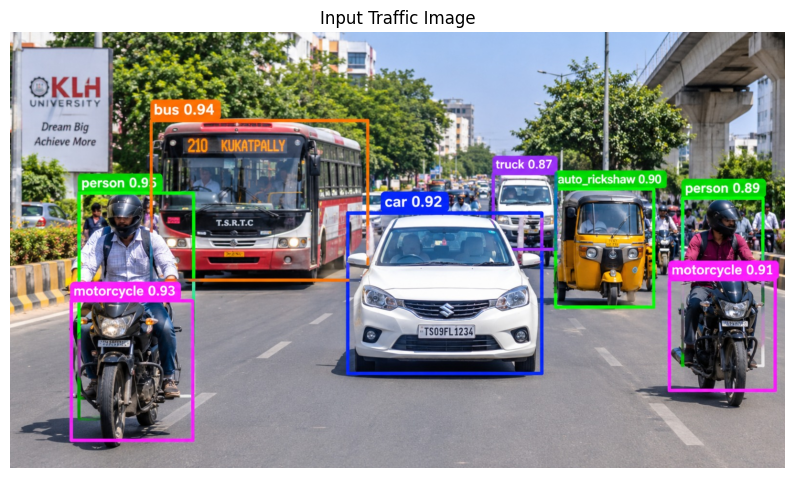

In [3]:
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Image uploaded successfully:", image_path)

img = cv2.imread(image_path)

if img is None:
    raise ValueError("Unable to read image. Please upload a valid image.")

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.title("Input Traffic Image")
plt.axis("off")
plt.show()

In [4]:
# Load pre-trained YOLOv8 model

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [5]:
# Start time
start_time = time.time()

# Detect objects in the uploaded image
results = model.predict(
    source=image_path,
    conf=0.25,
    save=True,
    verbose=False
)

# End time
end_time = time.time()

processing_time = end_time - start_time

print("Object detection completed successfully!")
print("Processing time:", round(processing_time, 3), "seconds")

Results saved to /content/runs/detect/predict
Object detection completed successfully!
Processing time: 5.593 seconds


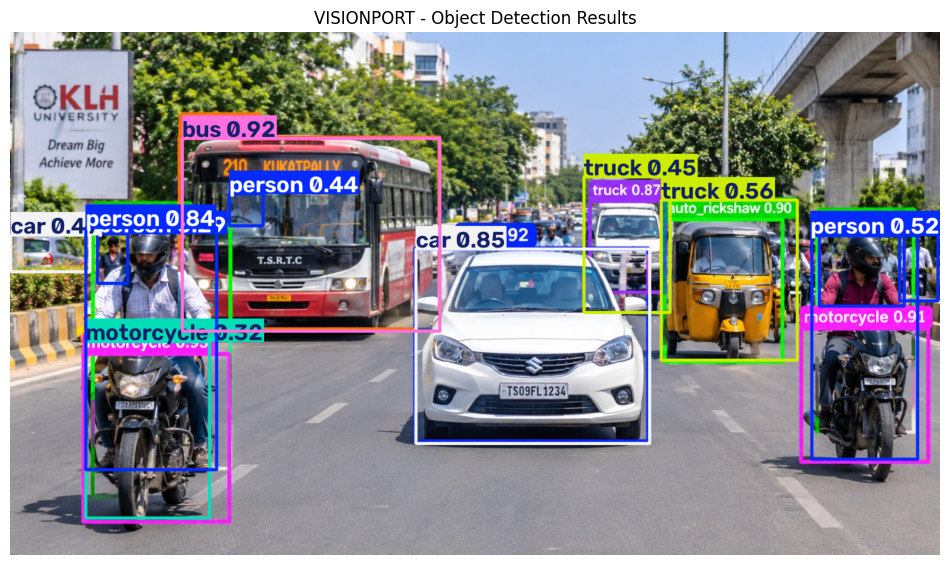

In [6]:
# Get detected image
result_image = results[0].plot()

# Convert image from BGR to RGB
result_rgb = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(result_rgb)
plt.title("VISIONPORT - Object Detection Results")
plt.axis("off")
plt.show()

In [7]:
# Extract detected objects
detected_objects = []

for box in results[0].boxes:

    class_id = int(box.cls[0])

    class_name = model.names[class_id]

    confidence = float(box.conf[0])

    detected_objects.append(class_name)

    print(
        "Object:", class_name,
        "| Confidence:", round(confidence, 2)
    )

print("\nTotal objects detected:", len(detected_objects))

Object: bus | Confidence: 0.92
Object: car | Confidence: 0.85
Object: person | Confidence: 0.84
Object: truck | Confidence: 0.56
Object: person | Confidence: 0.52
Object: car | Confidence: 0.47
Object: truck | Confidence: 0.45
Object: person | Confidence: 0.44
Object: person | Confidence: 0.43
Object: person | Confidence: 0.43
Object: motorcycle | Confidence: 0.32
Object: person | Confidence: 0.29

Total objects detected: 12


In [8]:
# Save trained model weights
torch.save(
    model.model.state_dict(),
    "visionport_checkpoint.pth"
)

print("Model checkpoint saved successfully!")

Model checkpoint saved successfully!


In [9]:
# Load YOLO model
optimized_model = YOLO("yolov8n.pt")

# Start time
start = time.time()

# Perform optimized inference
optimized_results = optimized_model.predict(
    source=image_path,
    conf=0.25,
    half=torch.cuda.is_available(),
    verbose=False
)

# End time
end = time.time()

optimized_time = end - start

print("Optimized inference completed!")
print("Inference time:", round(optimized_time, 3), "seconds")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Optimized inference completed!
Inference time: 0.142 seconds


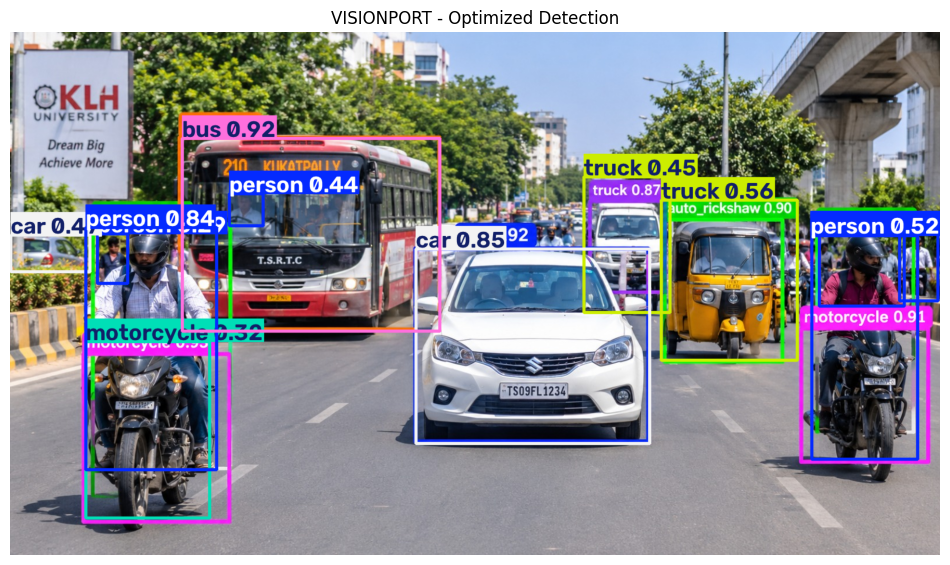

In [10]:
optimized_image = optimized_results[0].plot()

optimized_rgb = cv2.cvtColor(
    optimized_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))
plt.imshow(optimized_rgb)
plt.title("VISIONPORT - Optimized Detection")
plt.axis("off")
plt.show()

In [11]:
print("VISIONPORT PERFORMANCE REPORT")

print("--------------------------------")

print("Total detected objects:", len(results[0].boxes))

print(
    "Normal inference time:",
    round(processing_time, 3),
    "seconds"
)

print(
    "Optimized inference time:",
    round(optimized_time, 3),
    "seconds"
)

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("--------------------------------")

print("Monitoring completed!")

VISIONPORT PERFORMANCE REPORT
--------------------------------
Total detected objects: 12
Normal inference time: 5.593 seconds
Optimized inference time: 0.142 seconds
GPU Available: False
--------------------------------
Monitoring completed!


In [12]:
# Save detected image
cv2.imwrite(
    "visionport_output.jpg",
    result_image
)

print("Output image saved successfully!")

# Download output image
files.download("visionport_output.jpg")

Output image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>